# Thực nghiệm 2.5 — Tái thiết kế trực quan hóa Golub et al. (1999)

**Phụ trách:** Thành viên 5 (TV5)  
**Mục tiêu:** Hiện đại hóa các hình trực quan kinh điển trong bài báo tiên phong của Golub et al. (Science, 1999):
- **Fig. 2**: Khám phá lớp không giám sát bằng mạng Self-Organizing Maps (SOM 1x2 và 2x2), đối chiếu với kết quả bài báo và chiếu không gian PCA.
- **Fig. 3A**: (Chờ TV1 tích hợp `GolubWeightedVoting`) Phân bố Prediction Strength (PS) của 50 gen đặc trưng.
- **F04 (hình bổ sung của nhóm)**: Đánh giá Logistic Regression và phân tích lỗi trên tập kiểm tra độc lập (34 bệnh nhân), làm rõ mẫu nghi ngờ (mẫu 66) và các yếu tố gây nhiễu từ nguồn thu thập (loại mô BM/PB, bệnh viện).

Tuân thủ nghiêm ngặt **Style Guide** (`docs/style_guide.md`) và quyết định kiến trúc **ADR-014 / ADR-061**.

In [1]:
import warnings
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# Xac dinh thu muc goc du an
p = Path.cwd()
ROOT = None
while p != p.parent:
    if (p / 'src' / 'load.py').exists():
        ROOT = p
        break
    p = p.parent
if ROOT is None:
    ROOT = Path(r'C:\Users\pinkc\2026.1\Golub-project')

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.load import load_golub
from src.evaluate import evaluate, _baseline_pipeline
from src.viz import save_figure
from src.viz_redesign import plot_fig2_som_redesign, plot_fig3a_prediction_strength, plot_fig4_error_analysis
from src.config import PROJECT_ROOT

print('Da nap thanh cong cac module tu:', ROOT)


Da nap thanh cong cac module tu: C:\Users\pinkc\2026.1\Golub-project


## 1. Nạp dữ liệu tầng curated

`load_golub("curated")` đọc ma trận `X_log10.parquet` đã threshold và log10. Pipeline Logistic Regression fit các bước lọc và chọn gen trên tập train.

In [ ]:
X_cu, samples = load_golub('curated')
print(f'Curated log10: {X_cu.shape[0]} mẫu × {X_cu.shape[1]} probe')
display(samples.head())

## 2. Tái thiết kế Fig 2 — Khám phá lớp bằng Self-Organizing Maps (SOM)

Bài báo Golub (1999) sử dụng SOM để phát hiện phân cụm tự nhiên:
- SOM 1x2 tách phần lớn ALL vào A1 (24/27 ALL, 1/11 AML) và AML vào A2 (10/11 AML, 3/27 ALL).
- Bản thiết kế lại cải tiến:
  1. Thêm biểu đồ cột đối chiếu trực quan thành phần cụm bài báo vs kết quả nhóm.
  2. Chiếu 2D trên không gian PCA PC1-PC2 kèm tâm nơ-ron SOM để làm rõ biên phân cụm.
  3. Phân tích SOM 2x2 (4 nơ-ron) để khảo sát phân nhóm phụ B-ALL và T-ALL.

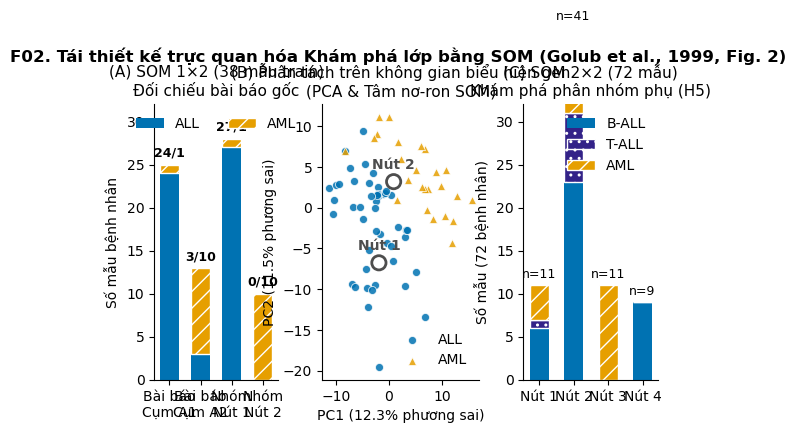

Da xuat F02_som_redesign cho ca report va slide.


In [3]:
fig2_report = plot_fig2_som_redesign(X_cu, samples, mode='report')
save_figure(fig2_report, 'F02_som_redesign', mode='report')
plt.show()

fig2_slide = plot_fig2_som_redesign(X_cu, samples, mode='slide')
save_figure(fig2_slide, 'F02_som_redesign', mode='slide')
plt.close(fig2_slide)
print('Da xuat F02_som_redesign cho ca report va slide.')

## 3. Tái thiết kế Fig 3A — Định lượng độ tin cậy dự đoán (Prediction Strength - Golub Fig. 3A)

- Nạp dữ liệu `results/metrics/golub_ps.csv` do TV1 cung cấp từ mô hình Golub Weighted Voting.
- Phân bố giá trị PS theo lớp ALL/AML trên tập huấn luyện (LOOCV, 38 mẫu) và tập kiểm tra độc lập (34 mẫu).
- Làm rõ vùng không chắc chắn (Uncertain, $PS < 0.30$) và đối chiếu trường hợp mẫu 66 và mẫu 67.


Tong so mau PS: 72


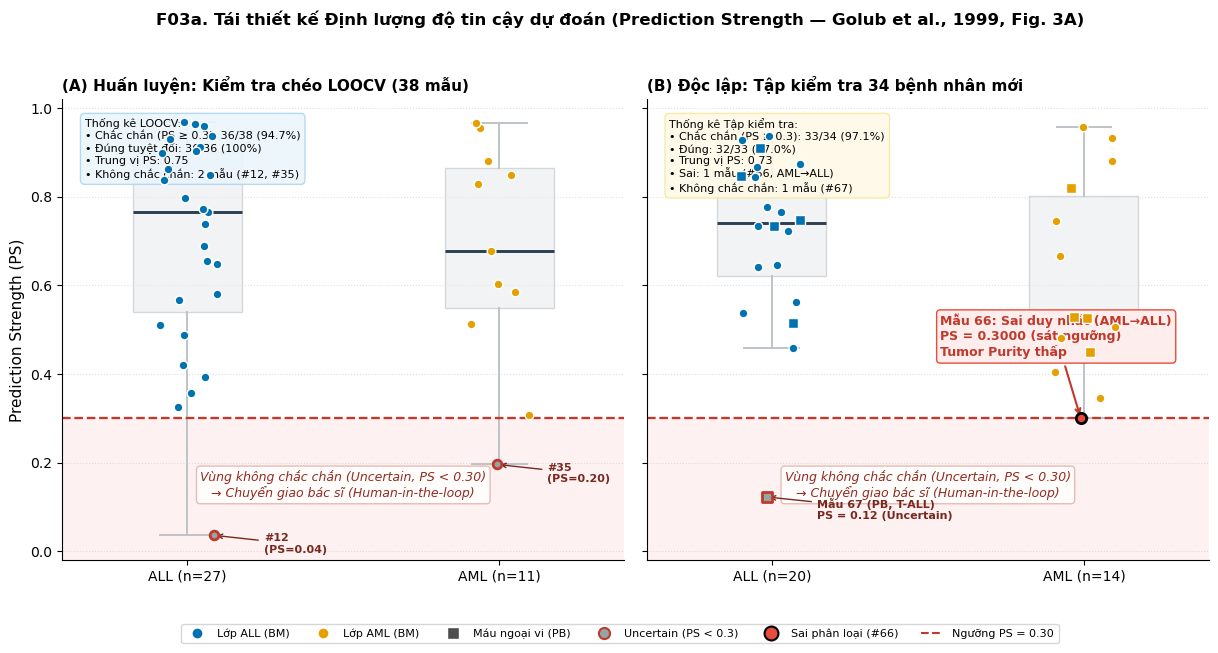

Da xuat F03a thanh cong vao results/figures/


In [4]:
ps_df = pd.read_csv(ROOT / 'results' / 'metrics' / 'golub_ps.csv')
print('Tong so mau PS:', len(ps_df))

# Ve va xuat ban report
fig3a_rep = plot_fig3a_prediction_strength(ps_df, mode='report')
path3a_rep = save_figure(fig3a_rep, 'F03a_prediction_strength', mode='report')
plt.show()

# Ve va xuat ban slide
fig3a_sld = plot_fig3a_prediction_strength(ps_df, mode='slide')
path3a_sld = save_figure(fig3a_sld, 'F03a_prediction_strength', mode='slide')
plt.close(fig3a_sld)
print('Da xuat F03a thanh cong vao results/figures/')


## 4. F04 — Phân tích lỗi Logistic Regression trên tập kiểm tra độc lập

Dải điểm AML 0,3–0,7 là vùng tham chiếu trực quan. Ngưỡng phân loại là 0,5.

In [ ]:
pipe = _baseline_pipeline(k=50)
res_test = evaluate(pipe, X_cu, samples['class'], scheme='original_split')
preds_test = res_test['predictions']
errors = preds_test.loc[preds_test['y_pred'].ne(preds_test['y_true'])]
print(f'{len(errors)}/{len(preds_test)} mẫu phân loại sai')
display(errors)

fig4_report = plot_fig4_error_analysis(preds_test, samples, mode='report')
save_figure(fig4_report, 'F04_error_analysis', mode='report')
plt.show()

fig4_slide = plot_fig4_error_analysis(preds_test, samples, mode='slide')
save_figure(fig4_slide, 'F04_error_analysis', mode='slide')
plt.close(fig4_slide)
print('Da xuat F04_error_analysis cho ca report va slide.')

## 5. Kết luận phân tích & Định hướng Quản trị dữ liệu

1. **Fig 2 (SOM):** Phân cụm tự nhiên 1x2 xác nhận dữ liệu gốc tách biệt mạnh giữa ALL và AML (34/38 đúng lớp đa số); lưới 2x2 chứng minh T-ALL không tách khỏi B-ALL ở cấp độ không giám sát.
2. **Fig 3A (Prediction Strength):** LOOCV đạt độ tin cậy cao 36/38 mẫu chắc chắn ($PS \ge 0.30$) và đúng 100%; cơ chế vùng ranh giới $PS < 0.30$ chuyển giao quyền quyết định cho bác sĩ lâm sàng.
3. **F04 (Logistic Regression):** Trên dữ liệu curated log10, mô hình phân loại đúng 33/34 mẫu, gồm cả 10 mẫu máu ngoại vi. Mẫu 66 là ca phân loại sai.
